# DS605 – Lab Assignment 7
## Image Representation, PCA, Eigenfaces and Face Recognition

Dataset: AT&T (ORL) Database of Faces. PCA is implemented with NumPy (not sklearn PCA). Scikit-learn is used only for Part D classifiers.

Run cells from top to bottom. The first cell downloads and extracts the dataset automatically. Internet access is required on first run. Alternatively, place `att_faces.zip` beside this notebook. Each part is in one code cell.

Dataset folder: C:\Users\H P\Desktop\202618004_lab_7
Images: 400 | Image size: 112 x 92
Features/image: 10304 | Subjects: 40
Intensity min/max/mean/std: 0.0 251.0 112.63 49.92


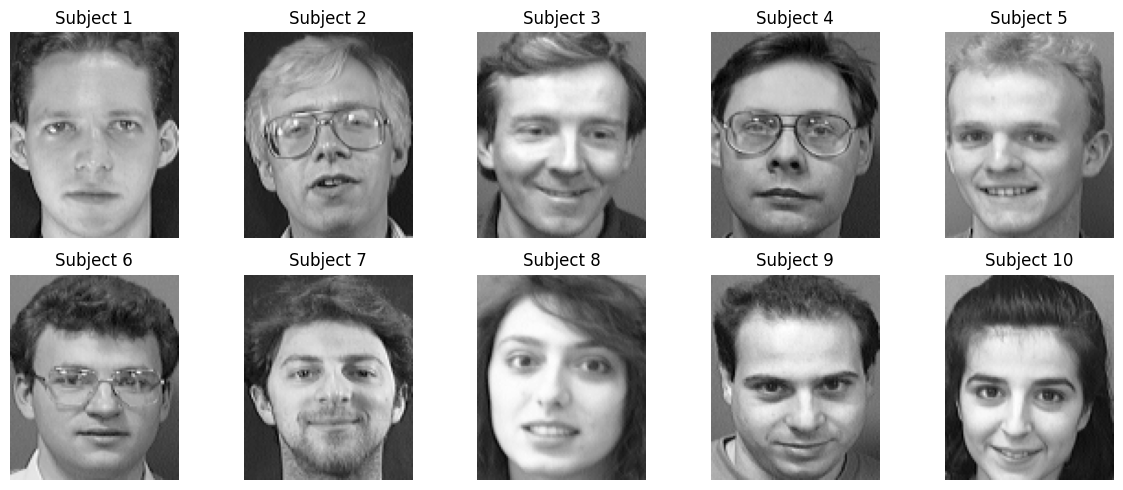

Train: (280, 10304) | Test: (120, 10304)
Part A completed.


In [2]:
# PART A — IMAGE REPRESENTATION
from pathlib import Path
import urllib.request, zipfile
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42
ZIP_PATH = Path("att_faces.zip")
DATA_URL = "https://www.cl.cam.ac.uk/research/dtg/attarchive/pub/data/att_faces.zip"

def locate_orl_root(search_from=Path(".")):
    """Find the directory that directly contains s1, s2, ..., s40."""
    for candidate in search_from.rglob("s1/1.pgm"):
        root = candidate.parent.parent
        if all((root / f"s{sid}" / "1.pgm").is_file() for sid in range(1, 41)):
            return root
    return None

# First check whether the dataset is already extracted, including nested folders.
DATA_DIR = locate_orl_root()

if DATA_DIR is None:
    if not ZIP_PATH.exists():
        print("Downloading AT&T/ORL face database...")
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

    if not zipfile.is_zipfile(ZIP_PATH):
        raise RuntimeError(
            f"{ZIP_PATH} is not a valid ZIP archive. Delete it and rerun this cell "
            "to download the dataset again."
        )

    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(".")

    # The archive may contain an extra enclosing folder, so locate the real root.
    DATA_DIR = locate_orl_root()

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate the ORL dataset. Expected a folder containing "
        "s1/1.pgm through s40/10.pgm. Check that att_faces.zip downloaded "
        "and extracted correctly."
    )

print("Dataset folder:", DATA_DIR.resolve())

images, labels = [], []
for sid in range(1, 41):
    folder = DATA_DIR / f"s{sid}"
    for iid in range(1, 11):
        image_path = folder / f"{iid}.pgm"
        if not image_path.is_file():
            raise FileNotFoundError(f"Missing image: {image_path.resolve()}")
        img = plt.imread(image_path)
        if img.ndim == 3:
            img = img.mean(axis=2)
        images.append(np.asarray(img, dtype=np.float64))
        labels.append(sid - 1)

images, y = np.stack(images), np.asarray(labels)
n_samples, height, width = images.shape
X = images.reshape(n_samples, -1)
print("Images:", n_samples, "| Image size:", f"{height} x {width}")
print("Features/image:", X.shape[1], "| Subjects:", len(np.unique(y)))
print("Intensity min/max/mean/std:", X.min(), X.max(),
      round(X.mean(), 2), round(X.std(), 2))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for sid, ax in enumerate(axes.flat):
    ax.imshow(images[np.where(y == sid)[0][0]], cmap="gray")
    ax.set_title(f"Subject {sid + 1}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Stratified split: 7 training images and 3 test images per subject.
rng = np.random.default_rng(RANDOM_STATE)
train_idx, test_idx = [], []
for sid in np.unique(y):
    idx = rng.permutation(np.where(y == sid)[0])
    train_idx.extend(idx[:7])
    test_idx.extend(idx[7:])

train_idx, test_idx = np.array(train_idx), np.array(test_idx)
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print("Train:", X_train.shape, "| Test:", X_test.shape)
assert len(X_train) == 280 and len(X_test) == 120
print("Part A completed.")

Relative eigenvalue difference (eigh vs SVD): 6.546957710893064e-16
Components for >=90% variance: 92


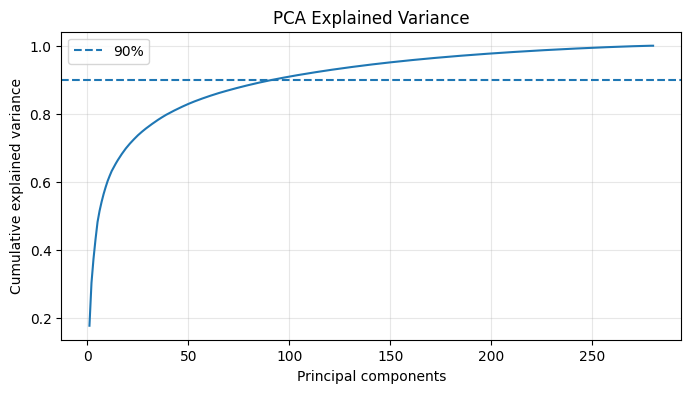

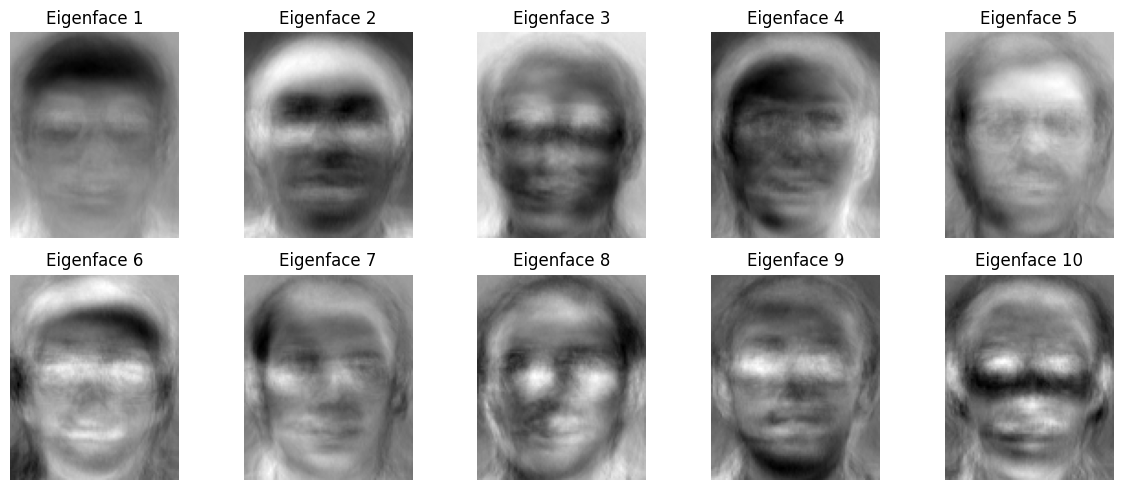

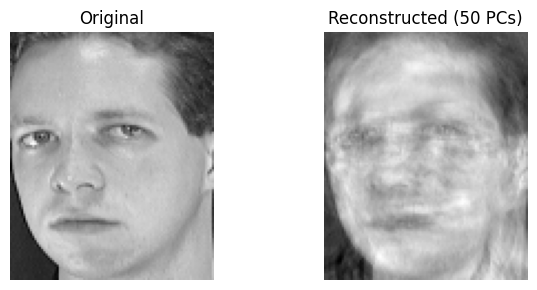

Reconstruction MSE: 241.1974
Dimensions: 10304 -> 50
Feature-count compression ratio: 206.08 :1
Part B completed.


In [3]:
# PART B — PCA, EIGENFACES AND COMPRESSION
import numpy as np
import matplotlib.pyplot as plt

mean_face = X_train.mean(axis=0)
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

# NumPy Gram-matrix eigendecomposition (dual covariance approach).
gram = X_train_centered @ X_train_centered.T
eigvals, eigvecs = np.linalg.eigh(gram)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = np.maximum(eigvals[order], 0), eigvecs[:, order]
valid = eigvals > 1e-10
eigvals = eigvals[valid]
eigenfaces_eig = (X_train_centered.T @ eigvecs[:, valid]) / np.sqrt(eigvals)[None, :]
eigenfaces_eig /= np.linalg.norm(eigenfaces_eig, axis=0, keepdims=True)

# NumPy SVD approach; use its right singular vectors as PCA directions.
U, singular_values, Vt = np.linalg.svd(X_train_centered, full_matrices=False)
eigenvalues = singular_values ** 2
eigenfaces = Vt.T
m = min(len(eigvals), len(eigenvalues))
print("Relative eigenvalue difference (eigh vs SVD):",
      np.linalg.norm(eigvals[:m] - eigenvalues[:m]) / max(np.linalg.norm(eigenvalues[:m]), 1e-12))

variance_ratio = eigenvalues / eigenvalues.sum()
cumulative = np.cumsum(variance_ratio)
k90 = np.searchsorted(cumulative, 0.90) + 1
print("Components for >=90% variance:", k90)

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(cumulative) + 1), cumulative)
plt.axhline(.90, linestyle="--", label="90%")
plt.xlabel("Principal components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA Explained Variance"); plt.grid(alpha=.3); plt.legend(); plt.show()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(eigenfaces[:, i].reshape(height, width), cmap="gray")
    ax.set_title(f"Eigenface {i+1}"); ax.axis("off")
plt.tight_layout(); plt.show()

n_components = min(50, eigenfaces.shape[1])
basis = eigenfaces[:, :n_components]
X_train_pca = X_train_centered @ basis
X_test_pca = X_test_centered @ basis
reconstruction = X_train_pca[0] @ basis.T + mean_face
mse = np.mean((X_train[0] - reconstruction) ** 2)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(X_train[0].reshape(height, width), cmap="gray"); axes[0].set_title("Original")
axes[1].imshow(reconstruction.reshape(height, width), cmap="gray"); axes[1].set_title(f"Reconstructed ({n_components} PCs)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("Reconstruction MSE:", round(float(mse), 4))
print("Dimensions:", X_train.shape[1], "->", n_components)
print("Feature-count compression ratio:", round(X_train.shape[1] / n_components, 2), ":1")
print("Part B completed.")

Raw-pixel 1-NN accuracy: 0.9750
PCA-space 1-NN accuracy: 0.9833
\nPCA-space report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       0.75      1.00      0.86         3
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00         3
           4       1.00      0.67      0.80         3
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         3
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         3
           9       1.00      1.00      1.00         3
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         3
          13       1.00      1.00      1.00         3
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00        

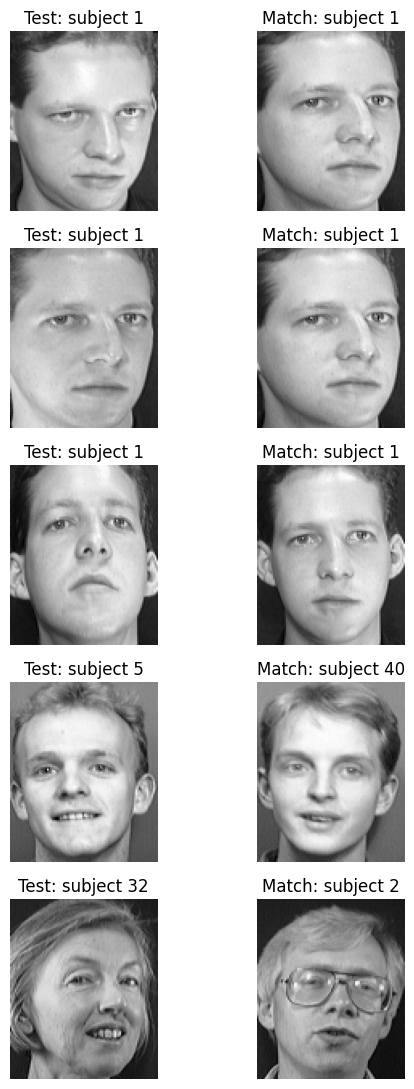

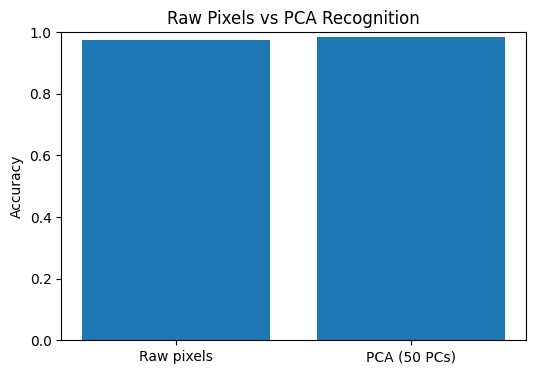

Correct PCA matches: 118 | Incorrect: 2
Part C completed.


In [4]:
# PART C — FACE RECOGNITION IN PCA SPACE
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report

def nearest_neighbor(train_X, train_y, test_X):
    predictions, indices, distances_out = [], [], []
    for sample in test_X:
        distances = np.linalg.norm(train_X - sample, axis=1)
        idx = int(np.argmin(distances))
        predictions.append(train_y[idx]); indices.append(idx); distances_out.append(distances[idx])
    return np.asarray(predictions), np.asarray(indices), np.asarray(distances_out)

raw_pred, raw_match, raw_dist = nearest_neighbor(X_train, y_train, X_test)
pca_pred, pca_match, pca_dist = nearest_neighbor(X_train_pca, y_train, X_test_pca)
raw_accuracy = accuracy_score(y_test, raw_pred)
pca_accuracy = accuracy_score(y_test, pca_pred)
print(f"Raw-pixel 1-NN accuracy: {raw_accuracy:.4f}")
print(f"PCA-space 1-NN accuracy: {pca_accuracy:.4f}")
print("\\nPCA-space report:")
print(classification_report(y_test, pca_pred, zero_division=0))

correct = np.where(pca_pred == y_test)[0]
incorrect = np.where(pca_pred != y_test)[0]
chosen = list(correct[:3]) + list(incorrect[:3])
if chosen:
    fig, axes = plt.subplots(len(chosen), 2, figsize=(6, 2.2 * len(chosen)))
    if len(chosen) == 1: axes = np.asarray([axes])
    for row, test_i in enumerate(chosen):
        train_i = pca_match[test_i]
        axes[row, 0].imshow(X_test[test_i].reshape(height, width), cmap="gray")
        axes[row, 0].set_title(f"Test: subject {y_test[test_i]+1}")
        axes[row, 1].imshow(X_train[train_i].reshape(height, width), cmap="gray")
        axes[row, 1].set_title(f"Match: subject {pca_pred[test_i]+1}")
        for ax in axes[row]: ax.axis("off")
    plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4))
plt.bar(["Raw pixels", f"PCA ({n_components} PCs)"], [raw_accuracy, pca_accuracy])
plt.ylim(0, 1); plt.ylabel("Accuracy"); plt.title("Raw Pixels vs PCA Recognition")
plt.show()
print("Correct PCA matches:", len(correct), "| Incorrect:", len(incorrect))
print("Part C completed.")

Model comparison:


C:\Users\H P\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\H P\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


,Model,Accuracy
4,1-NN PCA space,0.983333
3,1-NN raw pixels,0.975000
2,SVM (RBF),0.950000
1,Logistic Regression,0.950000
0,KNN (k=3),0.916667


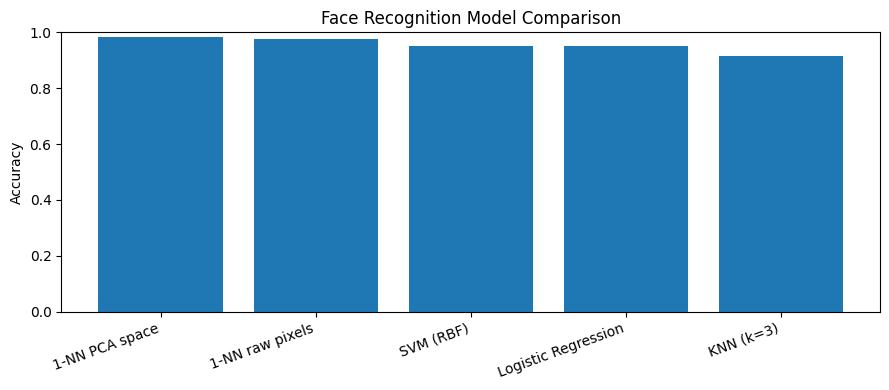

Best traditional classifier: Logistic Regression
              precision    recall  f1-score   support

           0       0.50      0.67      0.57         3
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00         3
           4       0.75      1.00      0.86         3
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         3
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         3
           9       1.00      1.00      1.00         3
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      0.33      0.50         3
          13       1.00      1.00      1.00         3
          14       1.00      1.00      1.00         3
          15       0.75      1.00      0.86         3
          16       1.00      1.0

,Components,SVM Accuracy
0,10,0.925000
1,20,0.941667
2,30,0.958333
3,40,0.966667
4,50,0.950000
5,75,0.966667
6,100,0.933333


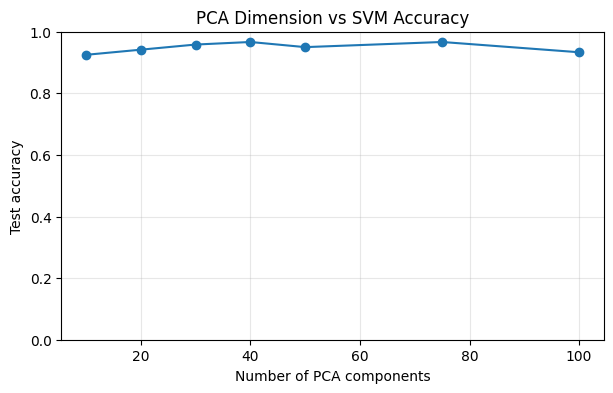

Part D completed.


In [5]:
# PART D — TRADITIONAL MACHINE LEARNING
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Standardize PCA features using training data only.
feature_mean = X_train_pca.mean(axis=0)
feature_std = X_train_pca.std(axis=0)
feature_std[feature_std == 0] = 1.0
train_scaled = (X_train_pca - feature_mean) / feature_std
test_scaled = (X_test_pca - feature_mean) / feature_std

models = {
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3, weights="distance"),
    "Logistic Regression": LogisticRegression(max_iter=3000, C=1.0),
    "SVM (RBF)": SVC(C=10, kernel="rbf", gamma="scale")
}
trained, rows = {}, []
for name, model in models.items():
    model.fit(train_scaled, y_train)
    pred = model.predict(test_scaled)
    trained[name] = model
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred)})

rows += [
    {"Model": "1-NN raw pixels", "Accuracy": raw_accuracy},
    {"Model": "1-NN PCA space", "Accuracy": pca_accuracy}
]
results_df = pd.DataFrame(rows).sort_values("Accuracy", ascending=False)
print("Model comparison:")
display(results_df)

plt.figure(figsize=(9, 4))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.ylim(0, 1); plt.ylabel("Accuracy"); plt.title("Face Recognition Model Comparison")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

best_name = max(trained, key=lambda name: accuracy_score(y_test, trained[name].predict(test_scaled)))
best_pred = trained[best_name].predict(test_scaled)
print("Best traditional classifier:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))

# Study the effect of PCA dimensionality on RBF-SVM performance.
component_counts = sorted(set(min(k, X_train_centered.shape[0] - 1) for k in [10, 20, 30, 40, 50, 75, 100]))
component_rows = []
for k in component_counts:
    basis_k = eigenfaces[:, :k]
    tr = X_train_centered @ basis_k
    te = X_test_centered @ basis_k
    mu, sigma = tr.mean(axis=0), tr.std(axis=0)
    sigma[sigma == 0] = 1.0
    tr, te = (tr - mu) / sigma, (te - mu) / sigma
    clf = SVC(C=10, kernel="rbf", gamma="scale")
    clf.fit(tr, y_train)
    component_rows.append({"Components": k, "SVM Accuracy": accuracy_score(y_test, clf.predict(te))})

component_df = pd.DataFrame(component_rows)
print("SVM accuracy by PCA component count:")
display(component_df)
plt.figure(figsize=(7, 4))
plt.plot(component_df["Components"], component_df["SVM Accuracy"], marker="o")
plt.xlabel("Number of PCA components"); plt.ylabel("Test accuracy")
plt.title("PCA Dimension vs SVM Accuracy"); plt.ylim(0, 1); plt.grid(alpha=.3); plt.show()
print("Part D completed.")